# 03 — Annotation review and target decision

Perera E. V. · J26-DS-339 · 2026-10-21. R006 compares pYIN with an independently implemented Praat autocorrelation estimator on the existing 20 TRAIN recordings. These examples were previously selected for the pilot and do not constitute a representative corpus-wide label audit. No human-verified corrected annotations are claimed.

In [1]:
from pathlib import Path
import json,sys
import numpy as np
import matplotlib.pyplot as plt
import librosa,librosa.display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/melody_understanding').exists())
sys.path.insert(0,str(ROOT/'src'))
from melody_understanding.audio import prepare_audio
from melody_understanding.annotations import read_midi_notes
report=json.loads((ROOT/'experiments/vishwa/results/annotation_review.json').read_text())
print('Configuration:',report['config'])
print('Review flags:',report['flags'])
print('Common voiced-frame estimator agreement:',report['macro_estimator_agreement'])
for row in report['recordings']:
    print(row['key'],row['review_flag'],round(row['estimator_agreement_50c'],3),round(row['pyin_median_error_semitones'],2),round(row['praat_median_error_semitones'],2))


Configuration: {'method': 'Praat autocorrelation', 'time_step_s': 0.011609977324263039, 'pitch_floor_hz': 32.70319566257483, 'pitch_ceiling_hz': 2093.004522404789, 'silence_threshold': 0.03, 'voicing_threshold': 0.45, 'mapping': 'nearest native frame within half a hop; no interpolation', 'flag_rule': 'shared octave: >=80% estimator agreement within 50 cents and both median errors within .75 semitone of same nonzero octave'}
Review flags: {'inspect_timing_and_pitch': 12, 'shared_octave_discrepancy': 8}
Common voiced-frame estimator agreement: 0.9272790685611512
F01_0101_0001_1_D inspect_timing_and_pitch 0.973 0.0 -0.03
F01_0487_0001_1_D inspect_timing_and_pitch 0.949 0.1 0.12
F02_0409_0002_2 inspect_timing_and_pitch 0.897 0.7 0.71
F02_0091_0003_1_D inspect_timing_and_pitch 0.896 0.3 0.29
F03_0444_0002_1_D inspect_timing_and_pitch 0.979 0.0 0.03
F03_0040_0002_1_D inspect_timing_and_pitch 0.978 0.0 0.02
F04_0410_0002_2 inspect_timing_and_pitch 0.903 -0.1 -0.11
F04_0077_0002_2_D inspect_ti

## Waveform, spectrum and pitch evidence

Choose two examples with high pYIN/MIDI agreement and two with shared octave discrepancies. Selection is only for illustration and is not used to change labels. Both pitch tracks are placed on original timestamps; Praat has unsupported edge frames because its analysis window must fit. Colored spectrogram bands are harmonics, so the strongest band alone does not determine fundamental pitch.

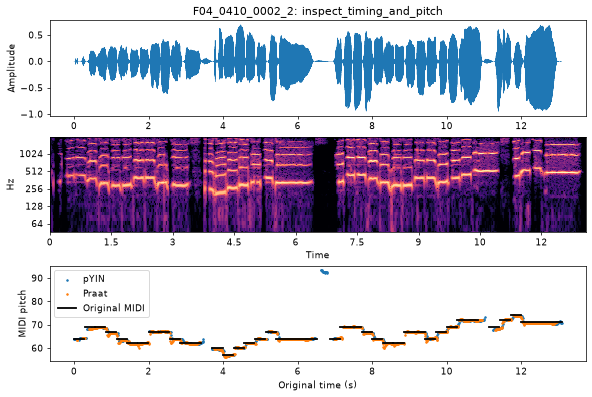

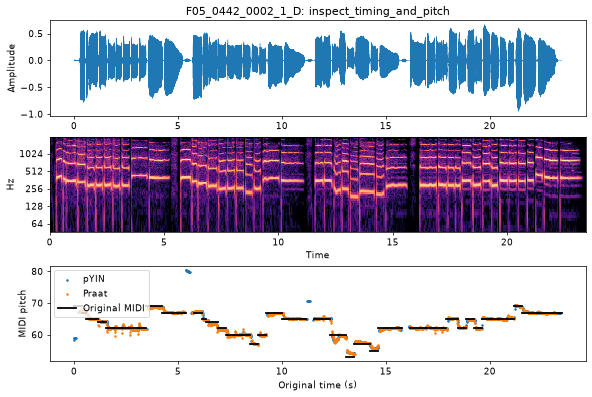

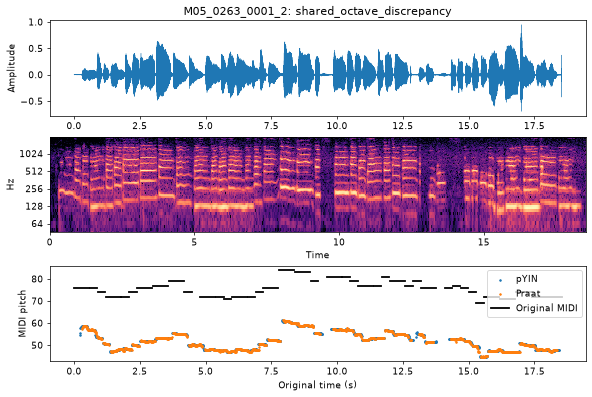

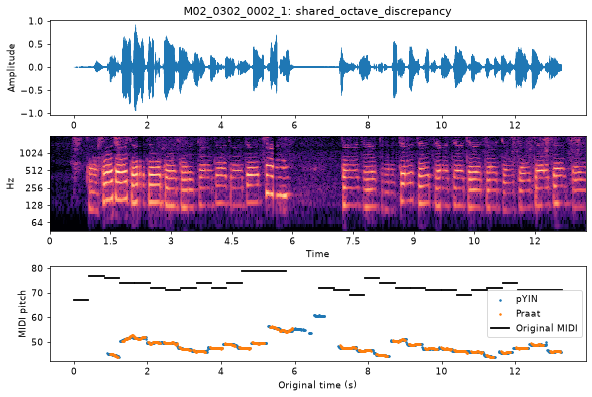

In [2]:
ordered=sorted(report['recordings'],key=lambda r:r['pyin_common_grid']['midi_frame_pitch_agreement_50c'],reverse=True)
octaves=sorted([r for r in report['recordings'] if r['review_flag']=='shared_octave_discrepancy'],key=lambda r:r['pyin_median_error_semitones'])
examples=ordered[:2]+octaves[:2]
for row in examples:
    key=row['key']
    audio=prepare_audio(ROOT/'datasets/humtrans/downloads/wav_data_sync_with_midi'/f'{key}.wav')
    ref,_=read_midi_notes(ROOT/'datasets/humtrans/downloads/midi_data'/f'{key}.mid')
    with np.load(ROOT/'datasets/humtrans/derived/research/pilot_features'/f'{key}.npz') as f:pyin={k:f[k] for k in f.files}
    with np.load(ROOT/'datasets/humtrans/derived/research/annotation_review'/f'{key}.npz') as f:praat={k:f[k] for k in f.files}
    fig,axes=plt.subplots(3,1,figsize=(9,6),dpi=65,constrained_layout=True)
    axes[0].plot(np.arange(len(audio.samples))/audio.sample_rate,audio.samples,lw=.4)
    axes[0].set(title=f"{key}: {row['review_flag']}",ylabel='Amplitude')
    spec=librosa.amplitude_to_db(np.abs(librosa.stft(audio.samples,n_fft=2048,hop_length=256)),ref=np.max)
    librosa.display.specshow(spec,sr=audio.sample_rate,hop_length=256,x_axis='time',y_axis='log',ax=axes[1],cmap='magma')
    axes[1].set(ylim=(32,2000),ylabel='Hz')
    for data,label in [(pyin,'pYIN'),(praat,'Praat')]:
        mask=data['voiced'] & np.isfinite(data['f0_hz'])
        axes[2].scatter(data['times_s'][mask],librosa.hz_to_midi(data['f0_hz'][mask]),s=3,label=label)
    for i,(start,end,pitch) in enumerate(ref):axes[2].plot([start,end],[pitch,pitch],color='black',lw=2,label='Original MIDI' if i==0 else None)
    axes[2].set(xlabel='Original time (s)',ylabel='MIDI pitch');axes[2].legend();plt.show()


## Decision D013 — preserve two target meanings

The observed estimator agreement strengthens the case for reviewing performed-pitch versus score-pitch semantics, but agreement is not ground truth. Keep acoustic F0 estimates with method provenance. Preserve original MIDI as **weak intended-score supervision**. Do not transpose individual recordings using predictions or filename suffixes alone.

The next feasibility experiment predicts 13 score classes (rest plus 12 pitch classes) from Mel features. It uses original MIDI timing with a fixed 100 ms boundary exclusion, recorded as a heuristic rather than a verified correction. Octave-dependent performed-pitch training remains pending verified labels. Beat, key, phrase and harmony supervision remain unsupported.

Reviewer status for the 20 cases remains `automated_evidence_only_human_review_pending`; visual inspection and algorithm agreement must not be represented as manual annotation validation.